Importaciones y Preparación de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid')
df = pd.read_parquet('../data/processed/calidad_aire_limpia.parquet').dropna()
columna_objetivo = 'MP2_5'
X = df.drop(columns=[columna_objetivo, 'Fecha', 'Date'], errors='ignore')
X = pd.get_dummies(X, drop_first=True)
y = df[columna_objetivo]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Entrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas")

Entrenamiento: 3474 filas | Prueba: 869 filas


C:\Users\mafer\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Entrenamiento y Tabla de Métricas

In [2]:
# 1. Entrenar los modelos
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)

modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
modelo_rf.fit(X_train, y_train)

# 2. Generar predicciones en el conjunto de PRUEBA
pred_lr = modelo_lr.predict(X_test)
pred_rf = modelo_rf.predict(X_test)

# 3. Calcular métricas
def calcular_metricas(y_real, y_pred, nombre_modelo):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    return {'Modelo': nombre_modelo, 'MAE': mae, 'RMSE': rmse, 'R²': r2}

metricas = pd.DataFrame([
    calcular_metricas(y_test, pred_lr, 'Regresión Lineal'),
    calcular_metricas(y_test, pred_rf, 'Random Forest')
])

print("\n--- Tabla de Rendimiento Comparado ---")
display(metricas.round(3))


--- Tabla de Rendimiento Comparado ---


,Modelo,MAE,RMSE,R²
0,Regresión Lineal,57.805,111.325,0.406
1,Random Forest,44.558,104.492,0.476


Gráficos de Errores (Real vs Predicho y Residuos)

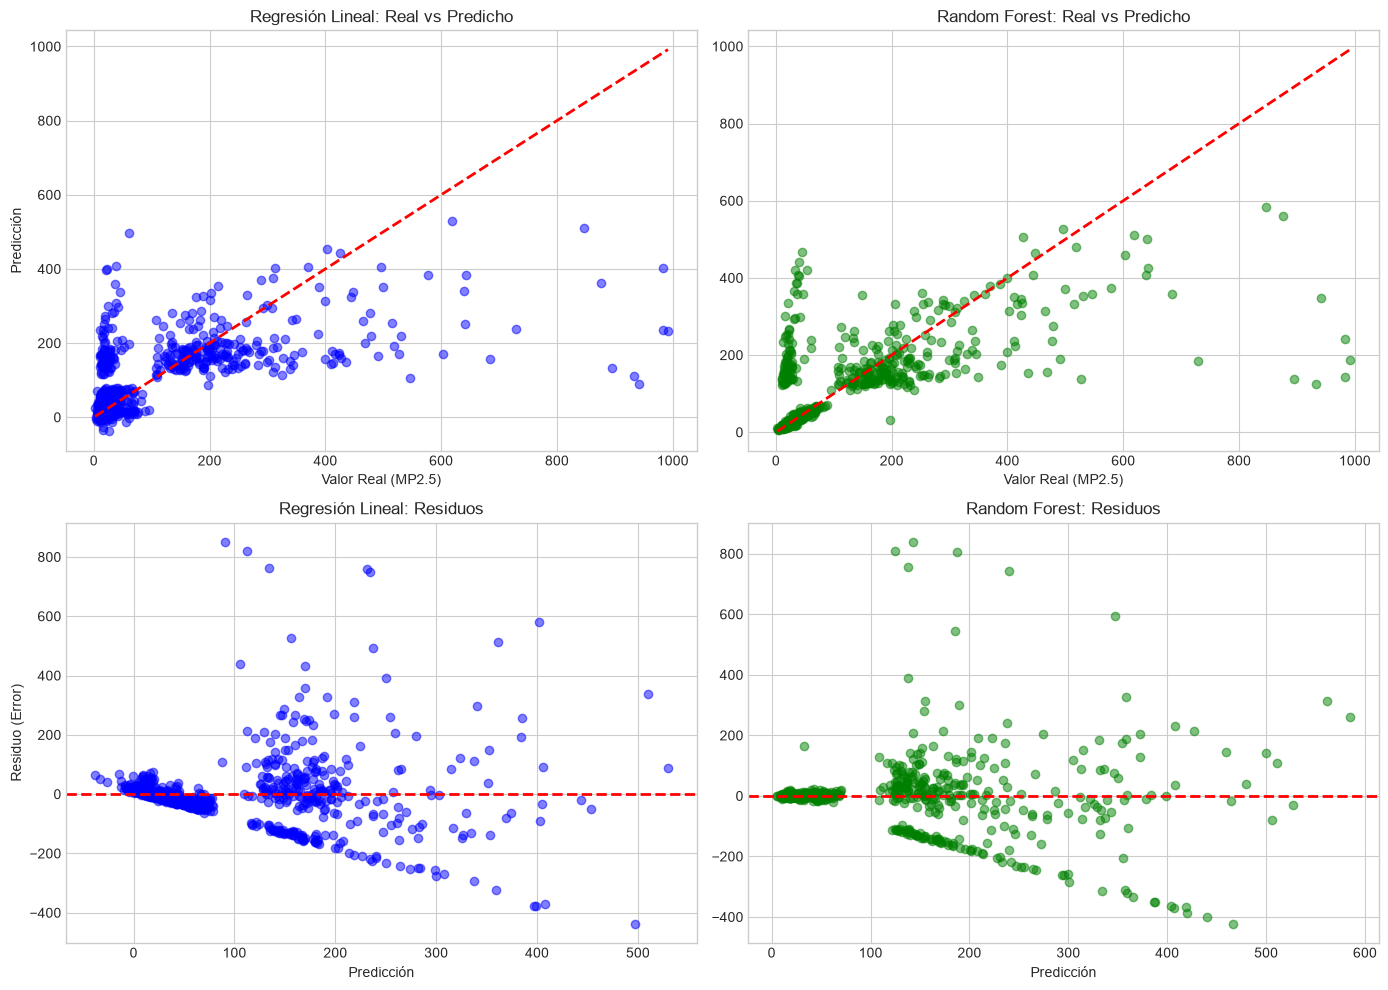

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Regresión Lineal: Real vs Predicho
axes[0, 0].scatter(y_test, pred_lr, alpha=0.5, color='blue')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 0].set_title('Regresión Lineal: Real vs Predicho')
axes[0, 0].set_xlabel('Valor Real (MP2.5)')
axes[0, 0].set_ylabel('Predicción')

# Random Forest: Real vs Predicho
axes[0, 1].scatter(y_test, pred_rf, alpha=0.5, color='green')
axes[0, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 1].set_title('Random Forest: Real vs Predicho')
axes[0, 1].set_xlabel('Valor Real (MP2.5)')

# Residuos
residuos_lr = y_test - pred_lr
residuos_rf = y_test - pred_rf

axes[1, 0].scatter(pred_lr, residuos_lr, alpha=0.5, color='blue')
axes[1, 0].axhline(0, color='r', linestyle='--', lw=2)
axes[1, 0].set_title('Regresión Lineal: Residuos')
axes[1, 0].set_xlabel('Predicción')
axes[1, 0].set_ylabel('Residuo (Error)')

axes[1, 1].scatter(pred_rf, residuos_rf, alpha=0.5, color='green')
axes[1, 1].axhline(0, color='r', linestyle='--', lw=2)
axes[1, 1].set_title('Random Forest: Residuos')
axes[1, 1].set_xlabel('Predicción')

plt.tight_layout()
plt.savefig('graficos_rendimiento.png', dpi=300)
plt.show()

Explicabilidad Global (SHAP Summary Plot)

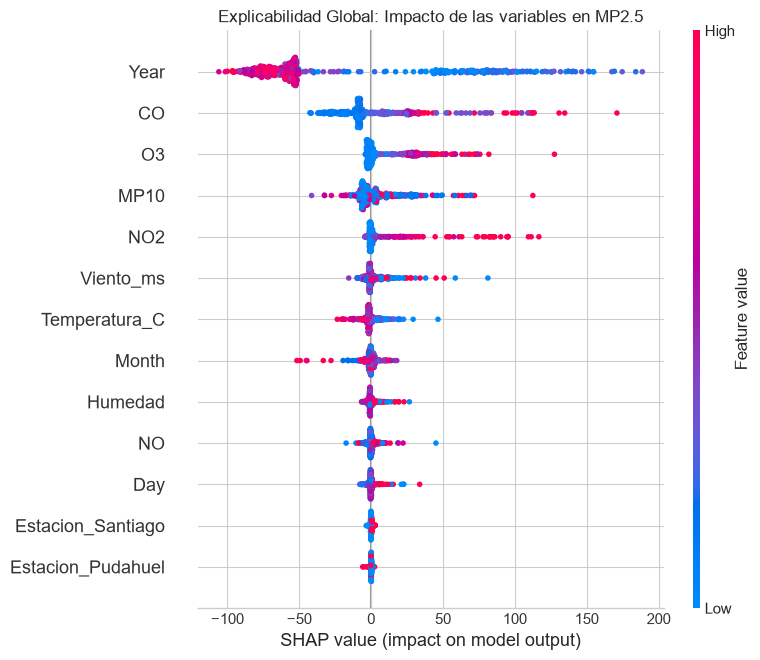

In [4]:
# Inicializar explicador SHAP para Random Forest
explainer = shap.TreeExplainer(modelo_rf)

# Calculamos los valores SHAP (tomamos una muestra de 500 para que sea rápido)
X_test_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)
shap_values = explainer(X_test_sample)

# Gráfico Global (Beeswarm)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title('Explicabilidad Global: Impacto de las variables en MP2.5')
plt.tight_layout()
plt.savefig('shap_global.png', dpi=300, bbox_inches='tight')
plt.show()

Explicabilidad Local (SHAP Waterfall)

--- CASO 1: ACIERTO ---
Valor Real: 13.00 | Predicción: 13.01


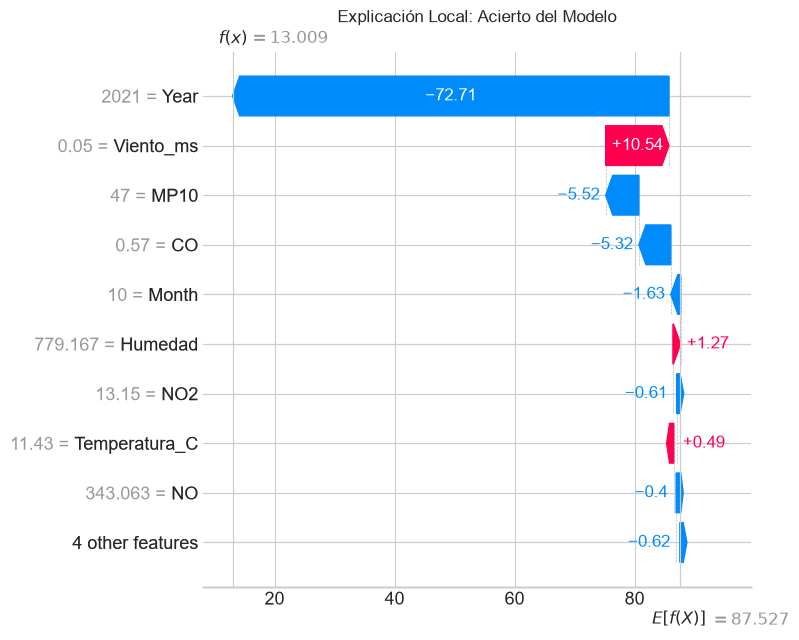


--- CASO 2: ERROR ALTO ---
Valor Real: 983.33 | Predicción: 143.38


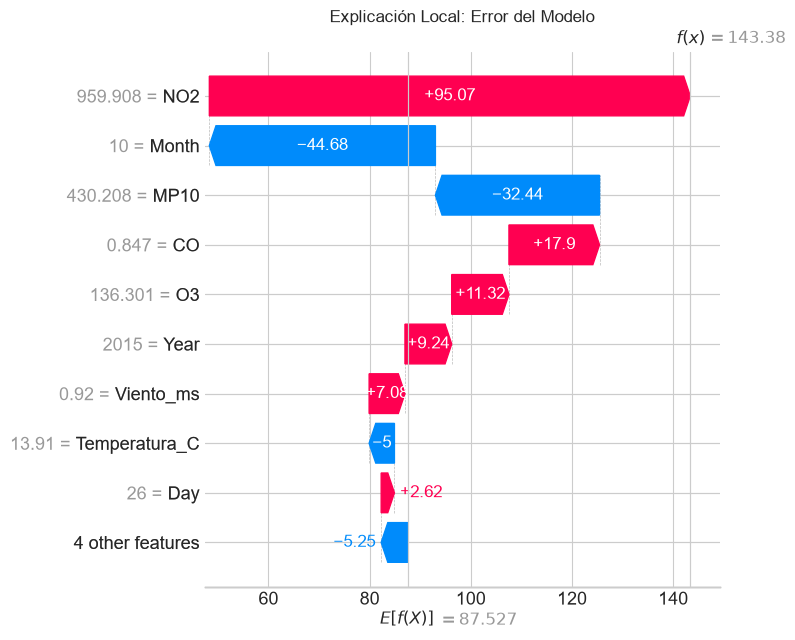

In [5]:
# Buscar el índice del mejor acierto y el peor error
errores_absolutos = np.abs(y_test - pred_rf)
idx_mejor = errores_absolutos.argmin()
idx_peor = errores_absolutos.argmax()

shap_values_local = explainer(X_test)
pos_mejor = np.where(X_test.index == y_test.index[idx_mejor])[0][0]
pos_peor = np.where(X_test.index == y_test.index[idx_peor])[0][0]

# --- Gráfico Local 1: El Acierto ---
print(f"--- CASO 1: ACIERTO ---")
print(f"Valor Real: {y_test.iloc[idx_mejor]:.2f} | Predicción: {pred_rf[idx_mejor]:.2f}")
plt.figure(figsize=(8, 5))
shap.plots.waterfall(shap_values_local[pos_mejor], show=False)
plt.title('Explicación Local: Acierto del Modelo')
plt.tight_layout()
plt.savefig('shap_acierto.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Gráfico Local 2: El Error ---
print(f"\n--- CASO 2: ERROR ALTO ---")
print(f"Valor Real: {y_test.iloc[idx_peor]:.2f} | Predicción: {pred_rf[idx_peor]:.2f}")
plt.figure(figsize=(8, 5))
shap.plots.waterfall(shap_values_local[pos_peor], show=False)
plt.title('Explicación Local: Error del Modelo')
plt.tight_layout()
plt.savefig('shap_error.png', dpi=300, bbox_inches='tight')
plt.show()